<a href="https://colab.research.google.com/github/sharakhaplan/Perceptron-Cat-Classifier/blob/main/CatPerceptron_FromScratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import urllib.request
import os

from PIL import Image
from scipy import ndimage

print("Kütüphaneler başarıyla yüklendi.")

Kütüphaneler başarıyla yüklendi.


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import h5py
import numpy as np

# Veri setlerinin yolları
train_path = '/content/drive/MyDrive/Dataset/CatPerceptron-FromScratch-Dataset/dataset/catvnoncat/train_catvnoncat.h5'

test_path = '/content/drive/MyDrive/Dataset/CatPerceptron-FromScratch-Dataset/dataset/catvnoncat/test_catvnoncat.h5'


# Eğitim verilerini oku
with h5py.File(train_path, 'r') as train_file:

    train_x_orig = np.array(train_file['train_set_x'][:])

    train_y = np.array(train_file['train_set_y'][:])


# Test verilerini oku
with h5py.File(test_path, 'r') as test_file:

    test_x_orig = np.array(test_file['test_set_x'][:])

    test_y = np.array(test_file['test_set_y'][:])

    classes = np.array(test_file['list_classes'][:])


print("Training images:", train_x_orig.shape)

print("Training labels:", train_y.shape)

print("Testing images:", test_x_orig.shape)

print("Testing labels:", test_y.shape)

print("Classes:", classes)

Training images: (209, 64, 64, 3)
Training labels: (209,)
Testing images: (50, 64, 64, 3)
Testing labels: (50,)
Classes: [b'non-cat' b'cat']


In [5]:
# veri setinin boyularının incelenmesi
print("Training images:", train_x_orig.shape)

print("Training labels:", train_y.shape)

print("Testing images:", test_x_orig.shape)

print("Testing labels:", test_y.shape)

print("Classes:", classes)

Training images: (209, 64, 64, 3)
Training labels: (209,)
Testing images: (50, 64, 64, 3)
Testing labels: (50,)
Classes: [b'non-cat' b'cat']


Label: Non-Cat


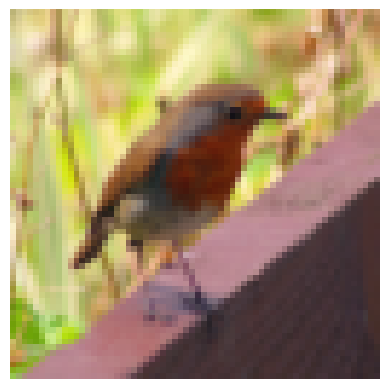

In [6]:
# veri setlerinin görselleştirilmesi
index = 10

plt.imshow(train_x_orig[index])

if train_y[index] == 1:
    print("Label: Cat")
else:
    print("Label: Non-Cat")

plt.axis('off')

plt.show()

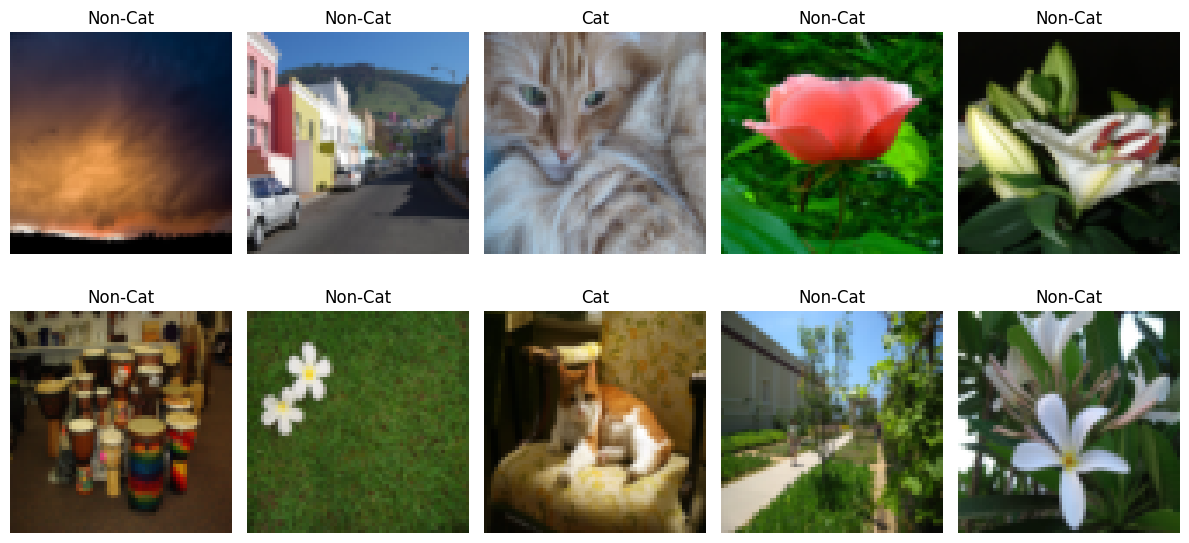

In [7]:
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(train_x_orig[i])

    label = "Cat" if train_y[i] == 1 else "Non-Cat"

    plt.title(label)

    plt.axis('off')

plt.tight_layout()

plt.show()

In [8]:
train_x_flatten = train_x_orig.reshape(
    train_x_orig.shape[0], -1
).T

test_x_flatten = test_x_orig.reshape(
    test_x_orig.shape[0], -1
).T


print("Training data shape:", train_x_flatten.shape)

print("Testing data shape:", test_x_flatten.shape)

Training data shape: (12288, 209)
Testing data shape: (12288, 50)


In [9]:
train_x = train_x_flatten / 255.0

test_x = test_x_flatten / 255.0


print("Training data normalized.")

print("Testing data normalized.")

print("Minimum pixel value:", train_x.min())

print("Maximum pixel value:", train_x.max())

Training data normalized.
Testing data normalized.
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [10]:
train_y = train_y.reshape(1, -1)

test_y = test_y.reshape(1, -1)


print("Training labels shape:", train_y.shape)

print("Testing labels shape:", test_y.shape)

Training labels shape: (1, 209)
Testing labels shape: (1, 50)


In [11]:
def sigmoid(z):

    z = np.clip(z, -500, 500)

    return 1 / (1 + np.exp(-z))

In [12]:
def initialize_parameters(n_features):

    np.random.seed(42)

    W = np.zeros((n_features, 1))

    b = 0.0

    return W, b

In [13]:
def forward_propagation(X, W, b):

    Z = np.dot(W.T, X) + b

    A = sigmoid(Z)

    return A

In [14]:
def compute_loss(Y, A):

    m = Y.shape[1]

    loss = np.sum((Y - A) ** 2) / m

    return loss

In [15]:
def update_parameters(X, Y, W, b, learning_rate):

    m = X.shape[1]

    # Shuffle training examples
    indices = np.random.permutation(m)

    X_shuffled = X[:, indices]
    Y_shuffled = Y[:, indices]

    # Process each example individually
    for i in range(m):

        x_i = X_shuffled[:, i:i+1]

        y_i = Y_shuffled[:, i:i+1]

        # Forward propagation
        z = np.dot(W.T, x_i) + b

        a = sigmoid(z)

        # Calculate gradient
        dz = 2 * (a - y_i) * a * (1 - a)

        dW = np.dot(x_i, dz.T)

        db = float(dz[0, 0])

        # Update parameters
        W = W - learning_rate * dW

        b = b - learning_rate * db

    return W, b

In [16]:
def predict(X, W, b):

    probabilities = forward_propagation(X, W, b)

    predictions = (probabilities >= 0.5).astype(int)

    return predictions

In [17]:
def perceptron_model(
    X_train,
    Y_train,
    X_test,
    Y_test,
    num_iterations=1000,
    learning_rate=0.001
):

    n_features = X_train.shape[0]

    # Initialize parameters
    W, b = initialize_parameters(n_features)

    costs = []

    # Training
    for epoch in range(num_iterations):

        # Update parameters using SGD
        W, b = update_parameters(
            X_train,
            Y_train,
            W,
            b,
            learning_rate
        )

        # Calculate training loss
        A = forward_propagation(
            X_train,
            W,
            b
        )

        cost = compute_loss(Y_train, A)

        costs.append(cost)

        if epoch % 100 == 0:

            print(
                f"Epoch {epoch}: Loss = {cost:.6f}"
            )

    # Make predictions
    train_predictions = predict(
        X_train,
        W,
        b
    )

    test_predictions = predict(
        X_test,
        W,
        b
    )

    # Calculate accuracy
    train_accuracy = np.mean(
        train_predictions == Y_train
    ) * 100

    test_accuracy = np.mean(
        test_predictions == Y_test
    ) * 100

    return {
        "W": W,
        "b": b,
        "costs": costs,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "train_predictions": train_predictions,
        "test_predictions": test_predictions
    }

In [19]:
model = perceptron_model(
    train_x,
    train_y,
    test_x,
    test_y,
    num_iterations=1000,
    learning_rate=0.001
)

Epoch 0: Loss = 0.428243
Epoch 100: Loss = 0.044687
Epoch 200: Loss = 0.019622
Epoch 300: Loss = 0.009645
Epoch 400: Loss = 0.007002
Epoch 500: Loss = 0.005072
Epoch 600: Loss = 0.004081
Epoch 700: Loss = 0.003471
Epoch 800: Loss = 0.002924
Epoch 900: Loss = 0.002593


In [20]:
print("========== MODEL RESULTS ==========")

print(
    "Training Accuracy:",
    round(model["train_accuracy"], 2),
    "%"
)

print(
    "Testing Accuracy:",
    round(model["test_accuracy"], 2),
    "%"
)

print(
    "Final MSE Loss:",
    round(model["costs"][-1], 6)
)

print("===================================")

========== MODEL RESULTS ==========
Training Accuracy: 100.0 %
Testing Accuracy: 72.0 %
Final MSE Loss: 0.002322


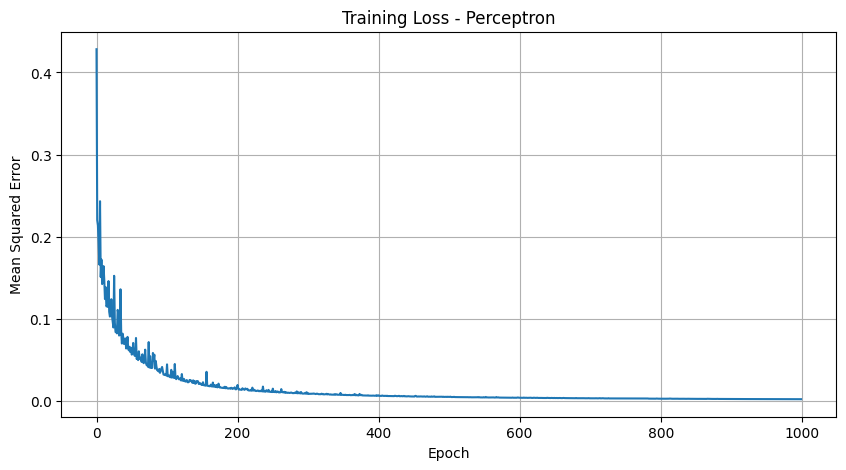

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(model["costs"])

plt.xlabel("Epoch")

plt.ylabel("Mean Squared Error")

plt.title("Training Loss - Perceptron")

plt.grid(True)

plt.show()

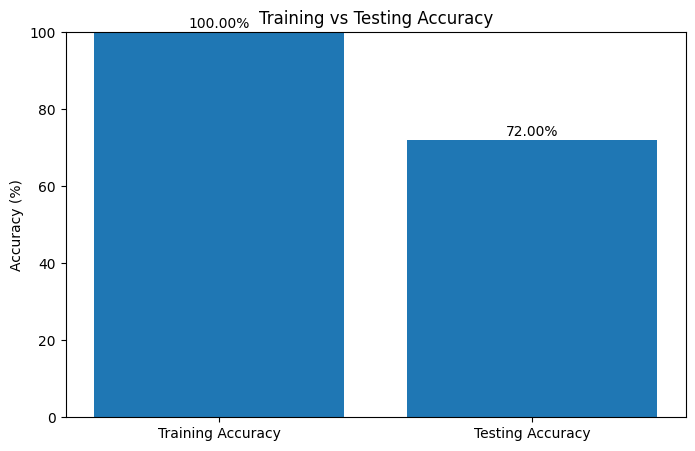

In [22]:
accuracies = [
    model["train_accuracy"],
    model["test_accuracy"]
]

labels = [
    "Training Accuracy",
    "Testing Accuracy"
]

plt.figure(figsize=(8, 5))

plt.bar(labels, accuracies)

plt.ylabel("Accuracy (%)")

plt.title("Training vs Testing Accuracy")

plt.ylim(0, 100)

for i, value in enumerate(accuracies):

    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

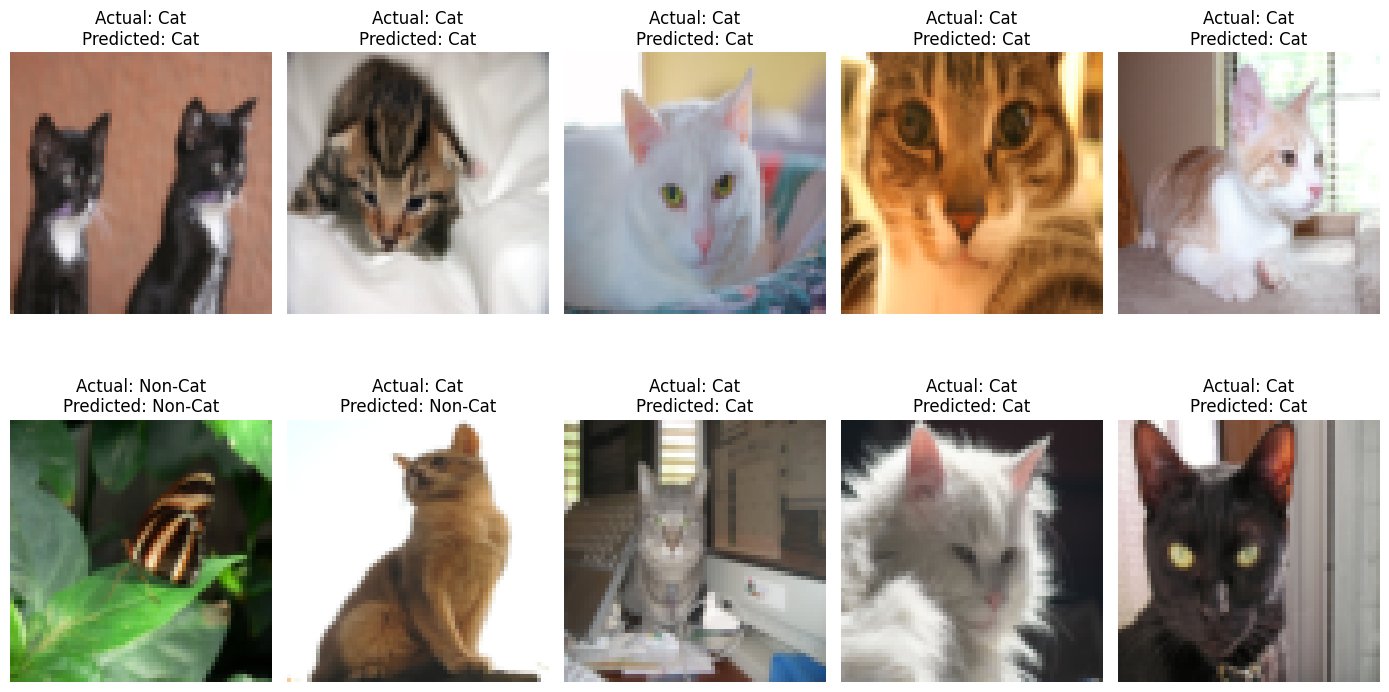

In [23]:
plt.figure(figsize=(14, 8))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = test_x_orig[i]

    actual = test_y[0, i]

    predicted = model["test_predictions"][0, i]

    actual_label = "Cat" if actual == 1 else "Non-Cat"

    predicted_label = "Cat" if predicted == 1 else "Non-Cat"

    plt.imshow(image)

    plt.title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

Number of incorrect predictions: 14
Incorrect image indices: [ 6 10 11 13 18 19 24 28 29 30 41 44 45 46]


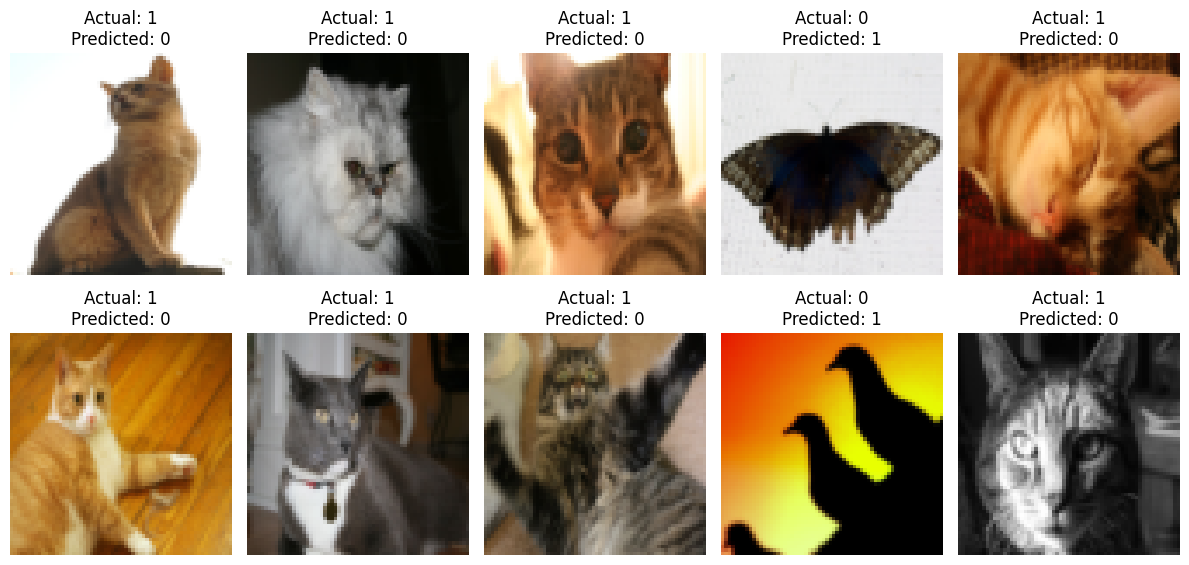

In [24]:
wrong_indices = np.where(
    model["test_predictions"][0] != test_y[0]
)[0]

print("Number of incorrect predictions:", len(wrong_indices))

print("Incorrect image indices:", wrong_indices)

if len(wrong_indices) > 0:

    plt.figure(figsize=(12, 6))

    for position, index in enumerate(wrong_indices[:10]):

        plt.subplot(2, 5, position + 1)

        plt.imshow(test_x_orig[index])

        actual = test_y[0, index]

        predicted = model["test_predictions"][0, index]

        plt.title(
            f"Actual: {actual}\nPredicted: {predicted}"
        )

        plt.axis("off")

    plt.tight_layout()

    plt.show()

In [26]:
results_path = '/content/drive/MyDrive/Module_16_Perceptron/results'

os.makedirs(results_path, exist_ok=True)

np.savez(
    os.path.join(results_path, 'perceptron_model.npz'),
    W=model["W"],
    b=model["b"]
)

print("Model saved successfully!")

Model saved successfully!
